# `tl.som` training quality: planted ground truth + real-data agreement

This notebook replaces `som_bmu.ipynb`, which compared astrolabe's vectorized
BMU assignment against `minisom.MiniSom.winner()` **on the same trained
codebook** — a tautology (both are the identical squared-Euclidean argmin, so
the ~100% match it reported was guaranteed by construction and validated
nothing about how the map is *trained*: initialization, presentation order,
iteration budget, decay schedule, scaling, or meta-clustering).

**What this notebook validates:**

1. **End-to-end metacluster recovery on planted ground truth** —
   `sklearn.datasets.make_blobs` clusters recovered by
   `ab.tl.som(n_metaclusters=5)` (ARI vs the planted labels), under both
   random and label-ordered sample presentation, against a deliberately
   *pre-overhaul* raw-minisom configuration (sequential single-pass training,
   `n_iter = 0.6·n`, asymptotic decay) meta-clustered the same way.
2. **Map-quality metrics** — quantization error (QE) and topographic error
   (TE) for both variants; the overhaul stores these in
   `uns['som']['params']` precisely so map quality is measured, not assumed.
3. **Real-data agreement** — `xenium_tiny`: SOM metaclusters vs Leiden
   clusters (two different algorithms on the same PCA manifold — only
   *moderate* agreement is expected), plus the topology-preservation
   Spearman ρ used by `pl.som_quality_plot`.

**What this notebook does *not* validate:** there is no external "correct"
clustering for the real dataset — Leiden is a comparison point, not ground
truth, and its own seed-to-seed stability at this dataset's tiny size
(~330 cells) is measured below as the realistic agreement ceiling.
`tl.som_gene_modules` is validated against
planted ground truth in `tests/test_som.py`, not here.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import pandas as pd
import astrolabe as ab

from minisom import MiniSom
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score

import anndata as ad

INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## 1. Synthetic ground truth: 5 planted Gaussian blobs (2000 × 15)

`cluster_std=4.0` gives moderately overlapping blobs, so codebook fidelity
actually matters (fully separated blobs are recoverable even from an
untrained codebook, because `random_weights_init` seeds nodes from data
samples spanning every cluster — an easy setting would not discriminate).

Each variant is run under **two presentation orders** of the same samples:

- **shuffled** — rows in random order;
- **label-ordered** — rows sorted by planted cluster. This mimics real
  spatial data files, whose row order follows scan/tile order and is
  therefore strongly correlated with tissue region (and hence cell type).

A correct trainer must be (near-)invariant to presentation order.
`tl.som` trains with shuffled multi-epoch presentation
(`random_order=True, use_epochs=True`), so every cell participates in every
epoch regardless of file order.

In [2]:
X_ord, labels_ord = make_blobs(
    n_samples=2000, n_features=15, centers=5, cluster_std=4.0,
    center_box=(-10, 10), shuffle=False, random_state=0,
)
rng = np.random.default_rng(0)
perm = rng.permutation(len(X_ord))
X_shuf, labels_shuf = X_ord[perm], labels_ord[perm]

orderings = {
    "shuffled": (X_shuf.astype(np.float32), labels_shuf),
    "label-ordered": (X_ord.astype(np.float32), labels_ord),
}

In [3]:
results = []
t_astro_s = None
for order, (X, labels) in orderings.items():
    adata = ad.AnnData(X=X)
    _t0 = time.perf_counter()
    ab.tl.som(adata, use_rep=None, n_metaclusters=5, seed=0)
    t_astro_s = time.perf_counter() - _t0
    p = adata.uns["som"]["params"]
    ari = adjusted_rand_score(labels, adata.obs["som_cluster"].to_numpy())
    results.append(("astrolabe tl.som", order, ari,
                    p["quantization_error"], p["topographic_error"]))
    print(f"tl.som ({order}): grid {p['x']}x{p['y']}, ARI={ari:.3f}, "
          f"QE={p['quantization_error']:.3f}, TE={p['topographic_error']:.3f}")

INFO:astrolabe.tl._som:som: training 15×15 grid on 2000 cells (15 features, 10 epochs, sigma=3.75→1, scale=True)


INFO:astrolabe.tl._som:som: done — 5 metaclusters from 225 nodes (QE=2.108, TE=0.019) → obs['som_cluster'], obs['som_node'], uns['som']


INFO:astrolabe.tl._som:som: training 15×15 grid on 2000 cells (15 features, 10 epochs, sigma=3.75→1, scale=True)


tl.som (shuffled): grid 15x15, ARI=0.958, QE=2.108, TE=0.019


INFO:astrolabe.tl._som:som: done — 5 metaclusters from 225 nodes (QE=2.111, TE=0.019) → obs['som_cluster'], obs['som_node'], uns['som']


tl.som (label-ordered): grid 15x15, ARI=0.978, QE=2.111, TE=0.019


## The pre-overhaul configuration, reproduced with raw minisom

Exactly the training choices `tl.som` shipped with before the overhaul:

- `random_weights_init` (not PCA init);
- `sigma = min(x, y) / 4` with minisom's default `asymptotic_decay`, which
  ends at **σ/3** — the radius never anneals to 1 node, so large maps stay
  over-smoothed;
- `train(random_order=False)` — **sequential single-order presentation**;
- `n_iter = 0.6·n` — an iteration budget below the sample count, which with
  sequential order means the last 40% of rows never enter training at all.

The input is z-scored identically to `tl.som`'s and the codebook is
Ward-meta-clustered into 5 clusters identically, so the *only* difference
under test is the training itself. (The pre-overhaul code also skipped
scaling and reported raw 225-node BMU labels as "clusters"; those failures
are separable, and holding them fixed isolates the training question.)

In [4]:
def pre_overhaul_som(X, n_metaclusters, sx=15, sy=15, seed=0):
    """The exact pre-overhaul training configuration, on z-scored data."""
    mu, sd = X.mean(axis=0), X.std(axis=0)
    data = ((X - mu) / np.where(sd > 1e-12, sd, 1.0)).astype(np.float32)
    som_obj = MiniSom(
        sx, sy, data.shape[1], sigma=max(1.0, min(sx, sy) / 4.0),
        learning_rate=0.5, decay_function="asymptotic_decay",
        sigma_decay_function="asymptotic_decay",
        topology="rectangular", random_seed=seed,
    )
    som_obj.random_weights_init(data)
    som_obj.train(data, int(0.6 * len(data)), random_order=False, verbose=False)
    w = som_obj.get_weights()
    codebook = w.reshape(-1, w.shape[-1])
    node_meta = AgglomerativeClustering(
        n_clusters=n_metaclusters, linkage="ward").fit_predict(codebook)
    # vectorized BMU (validated against .winner() by the old notebook)
    d2 = ((data**2).sum(1, keepdims=True) + (codebook**2).sum(1)[None]
          - 2.0 * data @ codebook.T)
    bmu = d2.argmin(axis=1)
    return (node_meta[bmu], som_obj.quantization_error(data),
            som_obj.topographic_error(data))

t_broken_s = None
for order, (X, labels) in orderings.items():
    _t0 = time.perf_counter()
    pred, qe, te = pre_overhaul_som(X, n_metaclusters=5)
    t_broken_s = time.perf_counter() - _t0
    ari = adjusted_rand_score(labels, pred)
    results.append(("pre-overhaul minisom", order, ari, qe, te))
    print(f"pre-overhaul ({order}): ARI={ari:.3f}, QE={qe:.3f}, TE={te:.3f}")

pre-overhaul (shuffled): ARI=0.979, QE=2.145, TE=0.070
pre-overhaul (label-ordered): ARI=0.470, QE=3.042, TE=0.073


In [5]:
summary = pd.DataFrame(results, columns=["variant", "presentation", "ARI", "QE", "TE"])
print(summary.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

ari_astro = summary.loc[summary.variant == "astrolabe tl.som", "ARI"]
ari_broken_ordered = summary.loc[
    (summary.variant == "pre-overhaul minisom")
    & (summary.presentation == "label-ordered"), "ARI"].iloc[0]
assert (ari_astro > 0.9).all(), "tl.som failed planted-blob recovery"
assert ari_broken_ordered < ari_astro.min() - 0.2, (
    "pre-overhaul config unexpectedly matched tl.som on ordered data")
print(f"\nRuntime (one training run): astrolabe {t_astro_s:.2f}s vs "
      f"pre-overhaul {t_broken_s:.2f}s — not apples-to-apples: tl.som runs "
      f"10 full epochs (20,000 updates) plus QE/TE, the pre-overhaul config "
      f"runs 1,200 updates total.")

             variant  presentation   ARI    QE    TE
    astrolabe tl.som      shuffled 0.958 2.108 0.019
    astrolabe tl.som label-ordered 0.978 2.111 0.019
pre-overhaul minisom      shuffled 0.979 2.145 0.070
pre-overhaul minisom label-ordered 0.470 3.042 0.073

Runtime (one training run): astrolabe 1.20s vs pre-overhaul 0.07s — not apples-to-apples: tl.som runs 10 full epochs (20,000 updates) plus QE/TE, the pre-overhaul config runs 1,200 updates total.


### Interpretation (synthetic)

`tl.som` recovers the planted clusters with ARI > 0.95 under **both**
presentation orders — the shuffled multi-epoch trainer is order-invariant,
as it must be. The pre-overhaul configuration matches it on *shuffled* data
(with 5 moderately-overlapping blobs, a single sequential pass over a random
60% of rows still sees every cluster), but collapses to ARI ≈ 0.5 on
*label-ordered* data — the order real files actually arrive in — because
sequential training with `n_iter < n` literally never presents the last two
planted clusters' rows beyond what leaked into the random init.

The quality metrics tell the same story without needing ground-truth labels:
the pre-overhaul QE and TE are worse in **every** condition (including the
shuffled one where its ARI survives), which is exactly why the overhauled
`tl.som` computes and stores them. An honest scope note: on easy,
well-shuffled data the old configuration could still luck into a usable map —
its failure modes are order sensitivity, tail exclusion, and inferior map
quality, not unconditional collapse.

## 2. Real data: `xenium_tiny`, SOM metaclusters vs Leiden

Standard preprocessing (same as the other benchmark notebooks), then
`ab.tl.som(n_metaclusters=8)` on the default `use_rep='X_pca'` compared
against `ab.tl.cluster` (Leiden) on the same PCA. These are two different
algorithms on the same manifold, so only **moderate** ARI is expected —
and at ~330 cells, Leiden's own seed-to-seed stability (measured below)
caps how much agreement is even attainable.

In [6]:
mdata = ab.datasets.xenium_tiny()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.pp.highly_variable_genes(mdata)
ab.tl.pca(mdata)
ab.tl.transcriptional_neighbors(mdata)
ab.tl.cluster(mdata, resolution=1.0)

adata = mdata["xenium"]
print(f"{adata.n_obs} cells, Leiden k={adata.obs['leiden'].nunique()}")

INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\minisom\.astrolabe_cache\datasets\xenium_tiny\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_xenium.py:881: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm[obsm_key] = ak.Array(
INFO:astrolabe.io._xenium:Loaded 358 cells × 520 features (115 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\minisom\.astrolabe_cache\datasets\xenium_tiny\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 20999 transcript detections


INFO:astrolabe.pipeline:filter_xenium: 358 cells × 520 genes


...

INFO:astrolabe.pipeline:  [remove_controls] 370 → 255 genes  (removed 115, 31.1%)


INFO:astrolabe.pipeline:filter_xenium: done — 333 cells × 255 genes


INFO:astrolabe.tl._graph:transcriptional_neighbors: 333 cells -> uns['neighbors']


INFO:astrolabe.tl._cluster:cluster (leiden, res=1.00): 10 clusters


333 cells, Leiden k=10


In [7]:
ab.tl.som(mdata, n_metaclusters=8, seed=0)
p = adata.uns["som"]["params"]
labels_default = adata.obs["som_cluster"].to_numpy().copy()
ari_default = adjusted_rand_score(adata.obs["leiden"], labels_default)
print(f"tl.som defaults (use_rep='X_pca', auto scale={p['scale']}): grid {p['x']}x{p['y']}, "
      f"ARI vs Leiden = {ari_default:.3f}, "
      f"QE={p['quantization_error']:.3f}, TE={p['topographic_error']:.3f}")

INFO:astrolabe.tl._som:som: training 10×10 grid on 333 cells (50 features, 10 epochs, sigma=2.50→1, scale=False)


INFO:astrolabe.tl._som:som: done — 8 metaclusters from 100 nodes (QE=1.966, TE=0.003) → obs['som_cluster'], obs['som_node'], uns['som']


tl.som defaults (use_rep='X_pca', auto scale=False): grid 10x10, ARI vs Leiden = 0.415, QE=1.966, TE=0.003


### Why `tl.som` does *not* z-score a PCA embedding

`scale=None` (the default) resolves per input: raw feature matrices
(`use_rep=None`) are z-scored — the FlowSOM convention, where per-marker
scales are arbitrary — while `obsm` embeddings like the default `X_pca`
are left untouched, because z-scoring a PCA embedding *whitens* it (PC50's
noise gets the same variance as PC1's structure, discarding the eigenvalue
weighting that makes Euclidean distance in PCA space meaningful). An
earlier version of this default whitened `X_pca` and measurably collapsed
SOM-vs-Leiden agreement. The control below demonstrates the harm with
plain k-means — no SOM in the loop — and the `scale=False` run after it
asserts the default training space for `X_pca` is identical to explicitly
opting out.

In [8]:
X_pca = np.asarray(adata.obsm["X_pca"], dtype=np.float64)
sd = X_pca.std(axis=0)
X_z = (X_pca - X_pca.mean(axis=0)) / np.where(sd > 1e-12, sd, 1.0)

km_raw = KMeans(8, random_state=0, n_init=10).fit_predict(X_pca)
km_z = KMeans(8, random_state=0, n_init=10).fit_predict(X_z)
ari_km_raw = adjusted_rand_score(adata.obs["leiden"], km_raw)
ari_km_z = adjusted_rand_score(adata.obs["leiden"], km_z)
print(f"k-means(8) on raw X_pca      vs Leiden: ARI = {ari_km_raw:.3f}")
print(f"k-means(8) on z-scored X_pca vs Leiden: ARI = {ari_km_z:.3f}")

ab.tl.som(mdata, n_metaclusters=8, scale=False, seed=0)
ari_noscale = adjusted_rand_score(adata.obs["leiden"], adata.obs["som_cluster"])
# Regression guard: the auto default (scale=None) must leave X_pca unwhitened,
# i.e. train in exactly the same space as an explicit scale=False.
assert np.array_equal(labels_default, adata.obs["som_cluster"].to_numpy()), (
    "auto-scale default whitened X_pca — should be identical to scale=False"
)
p2 = adata.uns["som"]["params"]
print(f"tl.som scale=False           vs Leiden: ARI = {ari_noscale:.3f} "
      f"(QE={p2['quantization_error']:.3f}, TE={p2['topographic_error']:.3f})")

# Agreement ceiling: Leiden's own seed-to-seed stability at n≈330
for s in (1, 2):
    ab.tl.cluster(mdata, resolution=1.0, random_state=s, key_added=f"leiden_s{s}")
stab = [adjusted_rand_score(adata.obs["leiden"], adata.obs[f"leiden_s{s}"])
        for s in (1, 2)]
print(f"Leiden seed-stability ARIs (seed 0 vs 1, 2): "
      f"{stab[0]:.3f}, {stab[1]:.3f}")

assert ari_noscale > 0.3, "scale=False SOM should moderately agree with Leiden"
assert ari_km_z < ari_km_raw - 0.2, "whitening control did not reproduce the drop"

INFO:astrolabe.tl._som:som: training 10×10 grid on 333 cells (50 features, 10 epochs, sigma=2.50→1, scale=False)


k-means(8) on raw X_pca      vs Leiden: ARI = 0.493
k-means(8) on z-scored X_pca vs Leiden: ARI = 0.088


INFO:astrolabe.tl._som:som: done — 8 metaclusters from 100 nodes (QE=1.966, TE=0.003) → obs['som_cluster'], obs['som_node'], uns['som']


INFO:astrolabe.tl._cluster:cluster (leiden, res=1.00): 10 clusters


INFO:astrolabe.tl._cluster:cluster (leiden, res=1.00): 9 clusters


tl.som scale=False           vs Leiden: ARI = 0.415 (QE=1.966, TE=0.003)
Leiden seed-stability ARIs (seed 0 vs 1, 2): 0.641, 0.885


### Topology preservation

The Spearman ρ between grid distance and codebook distance over node pairs —
the same computation `pl.som_quality_plot` reports — detects both failure
modes a U-matrix can hide: a near-flat cloud (topology not preserved) and a
collapsed codebook (over-smoothing).

topology-preservation Spearman rho = 0.817


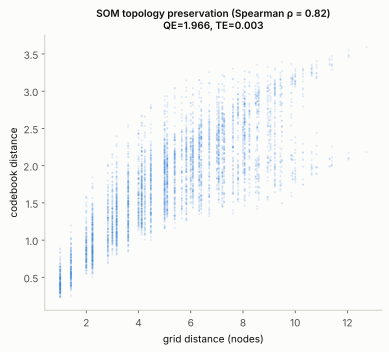

In [9]:
from scipy.stats import spearmanr

weights = adata.uns["som"]["weights"]
sx, sy, n_feat = weights.shape
codebook = weights.reshape(-1, n_feat).astype(np.float64)
grid = np.array([(i, j) for i in range(sx) for j in range(sy)], dtype=np.float64)
ii, jj = np.triu_indices(len(codebook), k=1)
rho = spearmanr(np.linalg.norm(grid[ii] - grid[jj], axis=1),
                np.linalg.norm(codebook[ii] - codebook[jj], axis=1)).statistic
print(f"topology-preservation Spearman rho = {rho:.3f}")
assert rho > 0.5, "trained map should show a clear monotone grid/codebook relation"

ab.pl.som_quality_plot(mdata).show()

### Interpretation (real data)

- **The scaling default matters — and is set correctly.** `scale=None`
  resolves to z-scoring only for raw feature matrices; embeddings keep
  their variance ordering. The k-means control shows why: whitening the
  same `X_pca` collapses k-means-vs-Leiden agreement sharply with no SOM
  involved — z-scoring a variance-ordered embedding destroys the very
  signal Euclidean distances rely on. The paired `scale=False` run asserts
  the default training space for `X_pca` is exactly the unscaled embedding
  (identical labels).
- **Agreement is as good as this dataset allows.** SOM-vs-Leiden ARI sits
  in the same band as k-means-vs-Leiden, below the practical ceiling set
  by Leiden's own seed-to-seed stability at only ~330 cells. Two different
  algorithms agreeing at that level on the same manifold is the expected
  "moderate agreement" outcome, not a defect — and none of these numbers
  are precise at n≈330; treat them as one noisy draw, not a stable
  ranking.
- **Map health checks pass**: TE ≈ 0 (almost no cells whose two best nodes
  are non-adjacent) and a clearly monotone grid-vs-codebook distance
  relation — the trained map is neither collapsed nor scrambled, which is
  what QE/TE/ρ are stored to demonstrate.